In [7]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/air_quality_daily.csv
/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/cities.csv
/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/weather_daily.csv


In [8]:
import pandas as pd
import numpy as np

path = "/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/air_quality_daily.csv"
df = pd.read_csv(path)

print(df.shape)
print(df.columns.tolist())
df.head()

(77400, 19)
['date', 'city', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm', 'india_aqi_pm_category']


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,dust_mean,aod_mean,us_aqi_max,hours_available,india_aqi,india_aqi_category,dominant_pollutant,india_aqi_pm,india_aqi_pm_category
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,0.0,0.18,61.0,24,72,Satisfactory,O3,23,Good
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,0.0,0.16,60.0,24,48,Good,O3,20,Good
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,0.0,0.15,56.0,24,75,Satisfactory,O3,20,Good
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,0.0,0.12,57.0,24,65,Satisfactory,O3,15,Good
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,0.0,0.10,51.0,24,69,Satisfactory,O3,11,Good


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77400 entries, 0 to 77399
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   77400 non-null  object 
 1   city                   77400 non-null  object 
 2   pm2_5_mean             77400 non-null  float64
 3   pm2_5_max              77400 non-null  float64
 4   pm10_mean              77400 non-null  float64
 5   pm10_max               77400 non-null  float64
 6   no2_mean               77400 non-null  float64
 7   so2_mean               77400 non-null  float64
 8   o3_8h_max              77400 non-null  float64
 9   co_8h_max              77400 non-null  float64
 10  dust_mean              77400 non-null  float64
 11  aod_mean               77400 non-null  float64
 12  us_aqi_max             77400 non-null  float64
 13  hours_available        77400 non-null  int64  
 14  india_aqi              77400 non-null  int64  
 15  in

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,77400,1548,2026-10-30,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,77400,50,Agartala,1548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pm2_5_mean,77400.0,NaN,NaN,NaN,35.47528,28.004142,0.48,16.73,28.1,45.32,279.78
pm2_5_max,77400.0,NaN,NaN,NaN,52.187394,41.190382,0.7,24.6,41.4,66.6,581.1
pm10_mean,77400.0,NaN,NaN,NaN,56.24475,62.627186,0.62,24.81,41.32,67.33,1788.14
pm10_max,77400.0,NaN,NaN,NaN,84.771127,108.129475,1.1,36.8,59.8,97.8,3166.5
no2_mean,77400.0,NaN,NaN,NaN,15.558651,13.446658,0.0,6.99,11.72,19.75,156.98
so2_mean,77400.0,NaN,NaN,NaN,13.13772,19.908095,0.03,4.03,7.81,14.46,505.24
o3_8h_max,77400.0,NaN,NaN,NaN,123.286942,40.486168,17.88,96.5,125.62,149.12,715.88
co_8h_max,77400.0,NaN,NaN,NaN,589.094026,476.457748,59.25,309.88,465.5,696.88,10595.5


In [10]:
df.isna().mean().sort_values(ascending=False)

date                     0.0
city                     0.0
pm2_5_mean               0.0
pm2_5_max                0.0
pm10_mean                0.0
pm10_max                 0.0
no2_mean                 0.0
so2_mean                 0.0
o3_8h_max                0.0
co_8h_max                0.0
dust_mean                0.0
aod_mean                 0.0
us_aqi_max               0.0
hours_available          0.0
india_aqi                0.0
india_aqi_category       0.0
dominant_pollutant       0.0
india_aqi_pm             0.0
india_aqi_pm_category    0.0
dtype: float64

In [7]:
df.iloc[:, :4].nunique()

date           1548
city             50
pm2_5_mean    11539
pm2_5_max      1165
dtype: int64

In [11]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].min(), df["date"].max())
print(df["city"].nunique(), "cities")

coverage = df.groupby("city")["date"].agg(["min", "max", "count"])
coverage

2022-08-05 00:00:00 2026-10-30 00:00:00
50 cities


,min,max,count
city,,,
Agartala,2022-08-05,2026-10-30,1548
Agra,2022-08-05,2026-10-30,1548
Ahmedabad,2022-08-05,2026-10-30,1548
Amritsar,2022-08-05,2026-10-30,1548
Bengaluru,2022-08-05,2026-10-30,1548
Bhopal,2022-08-05,2026-10-30,1548
Bhubaneswar,2022-08-05,2026-10-30,1548
Chandigarh,2022-08-05,2026-10-30,1548
Chennai,2022-08-05,2026-10-30,1548


In [12]:
# Duplicate city-date rows
print(df.duplicated(subset=["city", "date"]).sum())

# Impossible values (negatives)
num_cols = df.select_dtypes("number").columns
(df[num_cols] < 0).sum()

0


pm2_5_mean         0
pm2_5_max          0
pm10_mean          0
pm10_max           0
no2_mean           0
so2_mean           0
o3_8h_max          0
co_8h_max          0
dust_mean          0
aod_mean           0
us_aqi_max         0
hours_available    0
india_aqi          0
india_aqi_pm       0
dtype: int64

In [13]:
df = df.drop_duplicates(subset=["city", "date"])

In [14]:
df.to_csv("/kaggle/working/air_quality_clean.csv", index=False)

In [15]:
import os
print(os.listdir("/kaggle/working"))

['air_quality_clean.csv', '.virtual_documents']


In [16]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["city", "date"]).reset_index(drop=True)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

df.dtypes

date                     datetime64[ns]
city                             object
pm2_5_mean                      float64
pm2_5_max                       float64
pm10_mean                       float64
pm10_max                        float64
no2_mean                        float64
so2_mean                        float64
o3_8h_max                       float64
co_8h_max                       float64
dust_mean                       float64
aod_mean                        float64
us_aqi_max                      float64
hours_available                   int64
india_aqi                         int64
india_aqi_category               object
dominant_pollutant               object
india_aqi_pm                      int64
india_aqi_pm_category            object
year                              int32
month                             int32
month_name                       object
dtype: object

In [17]:
# 1. Days with incomplete hourly data
print(df["hours_available"].value_counts().sort_index())

# 2. Zeros that may be placeholders (e.g. dust_mean was 0.0 in your head())
(df.select_dtypes("number") == 0).mean().sort_values(ascending=False)

# 3. Ranges for sanity
df.describe().T[["min", "50%", "max"]]

# 4. Duplicates and negatives
print(df.duplicated(["city", "date"]).sum())
print((df.select_dtypes("number") < 0).sum().sum())

hours_available
24    77400
Name: count, dtype: int64
0
0


In [18]:
df["dominant_pollutant"].value_counts(normalize=True)
df.groupby("city")["dominant_pollutant"].agg(lambda s: s.value_counts().index[0]).value_counts()
df[["india_aqi", "india_aqi_pm"]].describe()

,india_aqi,india_aqi_pm
count,77400.00000,77400.000000
mean,145.90332,69.787403
std,65.61371,68.918626
min,28.00000,1.000000
25%,98.00000,29.000000
50%,140.00000,49.000000
75%,178.00000,81.000000
max,500.00000,500.000000


In [19]:
print(df["dominant_pollutant"].value_counts(normalize=True).round(3))

dominant_pollutant
O3       0.902
PM2.5    0.065
PM10     0.019
SO2      0.012
CO       0.002
NO2      0.001
Name: proportion, dtype: float64


In [20]:
top = df.groupby("city")["dominant_pollutant"].agg(lambda s: s.value_counts().index[0])
print(top.value_counts())

dominant_pollutant
O3    50
Name: count, dtype: int64


In [21]:
# How often are the values capped at 500?
print((df["india_aqi"] == 500).sum(), (df["india_aqi_pm"] == 500).sum())
print(df[df["india_aqi_pm"] == 500]["city"].value_counts().head(10))

229 229
city
Agra        145
Delhi        58
Kanpur       13
Ludhiana     11
Amritsar      1
Jaipur        1
Name: count, dtype: int64


In [22]:
# Delhi winter check (Nov-Jan) for validation
d = df[(df["city"] == "Delhi") & (df["date"].dt.month.isin([11, 12, 1]))]
print(d["pm2_5_mean"].describe())

count    368.000000
mean     110.871984
std       40.103996
min        0.620000
25%       81.960000
50%      105.695000
75%      137.890000
max      256.730000
Name: pm2_5_mean, dtype: float64


In [23]:
print(df["hours_available"].value_counts().sort_index())

hours_available
24    77400
Name: count, dtype: int64


In [24]:
print((df.select_dtypes("number") == 0).mean().sort_values(ascending=False).round(3))

dust_mean          0.113
no2_mean           0.001
pm10_mean          0.000
pm2_5_mean         0.000
pm10_max           0.000
so2_mean           0.000
o3_8h_max          0.000
pm2_5_max          0.000
co_8h_max          0.000
aod_mean           0.000
us_aqi_max         0.000
hours_available    0.000
india_aqi          0.000
india_aqi_pm       0.000
year               0.000
month              0.000
dtype: float64


In [25]:
# Is Agra's extreme count real? Look at when it happens
agra = df[(df["city"] == "Agra") & (df["india_aqi_pm"] == 500)]
print(agra.groupby(agra["date"].dt.to_period("M")).size())

date
2024-05     2
2024-06     1
2025-03    14
2025-04    20
2025-05    21
2025-06    13
2026-03    13
2026-04    22
2026-05    25
2026-06    14
Freq: M, dtype: int64


In [26]:
# Save the cleaned file
df.to_csv("/kaggle/working/air_quality_clean.csv", index=False)

In [27]:
# Compare Agra vs Delhi PM2.5 and PM10 by month (full years)
full = df[df["year"].between(2023, 2025)]
cmp = (full[full["city"].isin(["Agra", "Delhi"])]
       .groupby(["month", "city"])[["pm2_5_mean", "pm10_mean", "dust_mean"]].mean()
       .unstack().round(1))
print(cmp)

      pm2_5_mean        pm10_mean        dust_mean       
city        Agra  Delhi      Agra  Delhi      Agra  Delhi
month                                                    
1          116.3  121.4     155.4  159.7       7.8    7.4
2           68.4   69.9     115.2  109.2      56.3   40.7
3           69.0   65.1     300.0  195.9     431.0  229.3
4           58.2   52.4     312.5  178.3     515.5  241.4
5           63.6   64.0     342.5  209.6     588.3  291.1
6           54.9   58.9     270.2  185.8     459.0  267.9
7           33.3   48.2      54.0   83.9      27.1   52.4
8           29.9   49.4      55.3  131.6      43.1  167.6
9           35.9   44.0      64.5   81.2      37.6   52.8
10          56.7   63.4     118.3  129.3      96.1  103.8
11         107.8  103.9     149.4  143.6      32.9   32.7
12         110.5  108.6     128.2  124.6       3.8    3.0


In [28]:
# On Agra's capped days, which pollutant is dominant and what is the PM2.5/PM10 ratio?
a = df[(df["city"] == "Agra") & (df["india_aqi_pm"] == 500)]
print(a["dominant_pollutant"].value_counts())
print((a["pm2_5_mean"] / a["pm10_mean"]).describe())
print(a[["pm2_5_mean", "pm10_mean", "dust_mean"]].describe().round(1))

dominant_pollutant
PM10    145
Name: count, dtype: int64
count    145.000000
mean       0.139319
std        0.019164
min        0.099790
25%        0.125567
50%        0.135558
75%        0.149541
max        0.194137
dtype: float64
       pm2_5_mean  pm10_mean  dust_mean
count       145.0      145.0      145.0
mean        111.2      815.7     1380.8
std          27.9      252.8      442.1
min          51.8      511.1      686.8
25%          89.8      626.7     1072.2
50%         108.1      768.9     1286.4
75%         126.5      929.3     1604.6
max         210.1     1788.1     3145.8


In [29]:
print(df.duplicated(["city", "date"]).sum())
print((df.select_dtypes("number") < 0).sum().sum())
df.to_csv("/kaggle/working/air_quality_clean.csv", index=False)

0
0


# 02

**Exploratory Data Analysis**

city
Delhi        70.8
Agra         67.1
Ludhiana     63.7
Amritsar     63.7
Patna        59.5
Kolkata      56.6
Lucknow      56.4
Prayagraj    55.7
Varanasi     55.3
Kanpur       54.4
Name: pm2_5_mean, dtype: float64


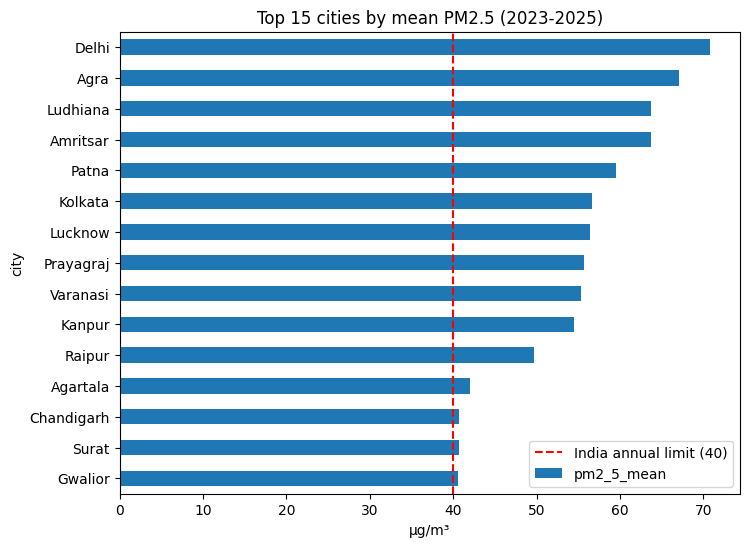

In [31]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("/kaggle/working/air_quality_clean.csv", parse_dates=["date"])
full = df[df["year"].between(2023, 2025)]

rank = full.groupby("city")["pm2_5_mean"].mean().sort_values(ascending=False)
print(rank.head(10).round(1))

rank.head(15).sort_values().plot(kind="barh", figsize=(8,6), title="Top 15 cities by mean PM2.5 (2023-2025)")
plt.xlabel("µg/m³"); plt.axvline(40, color="red", ls="--", label="India annual limit (40)"); plt.legend(); plt.show()

In [32]:
r = pd.DataFrame({
    "pm25_rank": full.groupby("city")["pm2_5_mean"].mean().rank(ascending=False),
    "pm10_rank": full.groupby("city")["pm10_mean"].mean().rank(ascending=False),
})
r["gap"] = r["pm25_rank"] - r["pm10_rank"]
print(r.sort_values("gap").round(0).head(10))   # cities much worse on PM10 than PM2.5
print(r.sort_values("gap").round(0).tail(10))

             pm25_rank  pm10_rank  gap
city                                  
Agartala          12.0       20.0 -8.0
Guwahati          25.0       31.0 -6.0
Bhubaneswar       16.0       21.0 -5.0
Kolkata            6.0       11.0 -5.0
Imphal            38.0       42.0 -4.0
Chandigarh        13.0       17.0 -4.0
Vijayawada        26.0       30.0 -4.0
Madurai           36.0       39.0 -3.0
Patna              5.0        8.0 -3.0
Nagpur            21.0       23.0 -2.0
                    pm25_rank  pm10_rank   gap
city                                          
Indore                   29.0       27.0   2.0
Mangaluru                37.0       35.0   2.0
Thiruvananthapuram       48.0       45.0   3.0
Puducherry               44.0       41.0   3.0
Chennai                  40.0       37.0   3.0
Gwalior                  15.0       12.0   3.0
Mumbai                   19.0       15.0   4.0
Kanpur                   10.0        3.0   7.0
Jaipur                   23.0       10.0  13.0
Jodhpur        

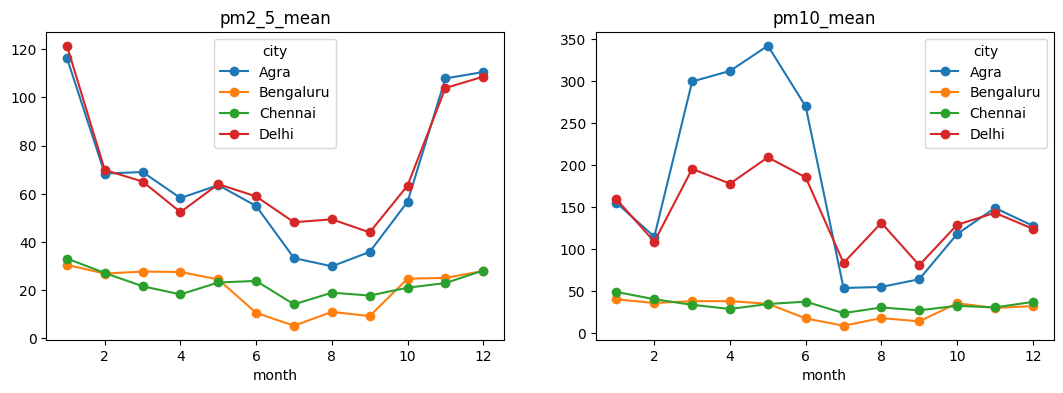

In [37]:
cities = ["Delhi", "Agra", "Bengaluru", "Chennai"]
fig, ax = plt.subplots(1, 2, figsize=(13,4))
for col, a in zip(["pm2_5_mean", "pm10_mean"], ax):
    full[full["city"].isin(cities)].groupby(["month","city"])[col].mean().unstack().plot(ax=a, marker="o", title=col)
plt.show()

In [38]:
def cat(p):  # based on India's PM2.5 24-hr breakpoints
    return pd.cut([p], [-1,30,60,90,120,250,1e9],
                  labels=["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"])[0]
full = full.assign(pm25_cat=full["pm2_5_mean"].apply(cat))
share = pd.crosstab(full["city"], full["pm25_cat"], normalize="index").mul(100).round(1)
print(share.sort_values("Poor", ascending=False).head(10))

pm25_cat   Good  Moderate  Poor  Satisfactory  Severe  Very Poor
city                                                            
Delhi       4.3      26.4  14.3          44.5     0.1       10.4
Agra       14.0      20.5  12.0          40.8     0.0       12.7
Patna      22.6      19.1  10.6          39.4     0.0        8.3
Kolkata    34.7      18.5  10.3          27.0     0.0        9.5
Lucknow    18.7      16.2  10.0          49.3     0.0        5.7
Prayagraj  21.5      15.3   9.0          47.6     0.0        6.5
Kanpur     21.4      16.6   8.9          47.7     0.0        5.4
Amritsar   12.8      17.7   8.6          49.9     0.1       10.9
Varanasi   20.5      16.0   7.6          49.4     0.0        6.6
Ludhiana   11.3      22.8   7.3          48.3     0.1       10.2


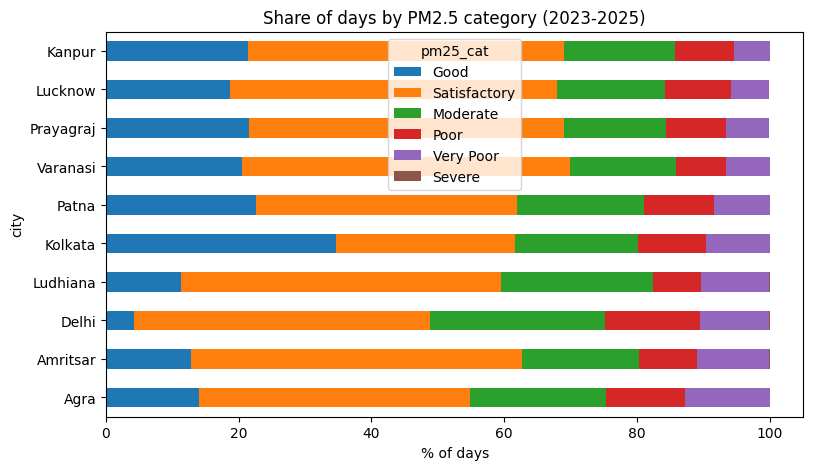

In [41]:
order = ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"]
share = share[order]
share.sort_values("Very Poor", ascending=False).head(10).plot(
    kind="barh", stacked=True, figsize=(9,5), title="Share of days by PM2.5 category (2023-2025)")
plt.xlabel("% of days"); plt.show()

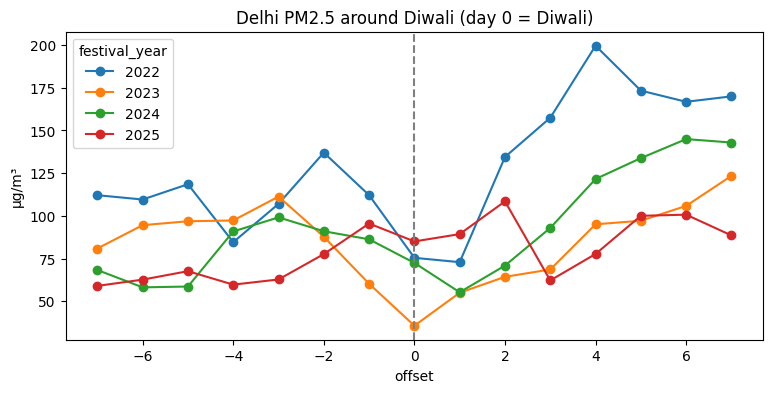

festival_year   2022   2023   2024   2025
offset                                   
-7             112.1   80.9   68.3   59.0
-6             109.6   94.6   58.2   62.7
-5             118.6   96.9   58.7   67.6
-4              84.6   97.3   90.9   59.8
-3             107.0  111.3   99.1   62.8
-2             137.0   87.8   91.0   77.6
-1             112.1   60.3   86.3   95.5
 0              75.5   35.7   72.5   85.1
 1              72.9   55.0   55.3   89.4
 2             134.5   64.3   70.9  108.5
 3             157.5   68.6   93.0   62.2
 4             199.6   95.1  121.6   77.7
 5             173.3   97.2  133.8  100.1
 6             166.8  105.9  145.0  100.7
 7             170.0  123.5  143.0   88.6


In [43]:
diwali = {
    2022: "2022-10-24",
    2023: "2023-11-12",
    2024: "2024-10-31",
    2025: "2025-10-20",
}

rows = []
for y, d in diwali.items():
    d = pd.Timestamp(d)
    sub = df[(df["city"] == "Delhi") &
             (df["date"].between(d - pd.Timedelta(days=7), d + pd.Timedelta(days=7)))].copy()
    sub["offset"] = (sub["date"] - d).dt.days
    sub["festival_year"] = y
    rows.append(sub[["festival_year", "offset", "pm2_5_mean"]])

dw = pd.concat(rows)
pivot = dw.pivot(index="offset", columns="festival_year", values="pm2_5_mean")
pivot.plot(figsize=(9, 4), marker="o", title="Delhi PM2.5 around Diwali (day 0 = Diwali)")
plt.ylabel("µg/m³")
plt.axvline(0, color="grey", ls="--")
plt.show()
print(pivot.round(1))

In [46]:
t = dw.pivot(index="offset", columns="festival_year", values="pm2_5_mean")
summary = pd.DataFrame({
    "before (-7..-1)": t.loc[-7:-1].mean(),
    "day 0": t.loc[0],
    "after (+4..+7)": t.loc[4:7].mean(),
}).round(1)
summary["change %"] = ((summary["after (+4..+7)"] / summary["before (-7..-1)"] - 1) * 100).round(0)
print(summary)

               before (-7..-1)  day 0  after (+4..+7)  change %
festival_year                                                  
2022                     111.6   75.5           177.4      59.0
2023                      89.9   35.7           105.4      17.0
2024                      78.9   72.5           135.8      72.0
2025                      69.3   85.1            91.8      32.0


In [47]:
ctrl = {}
for y, d in diwali.items():
    d = pd.Timestamp(d) - pd.Timedelta(days=30)
    s = df[(df["city"]=="Delhi") & (df["date"].between(d - pd.Timedelta(days=7), d + pd.Timedelta(days=7)))]
    ctrl[y] = [s[s["date"] < d]["pm2_5_mean"].mean(),
               s[s["date"] > d + pd.Timedelta(days=3)]["pm2_5_mean"].mean()]
print(pd.DataFrame(ctrl, index=["before","after"]).T.round(1))

      before  after
2022    71.3   90.7
2023    54.3   39.5
2024    48.2   48.1
2025    53.1   48.1


In [48]:
shifts = [20, 30, 40, 50]
out = {}
for sh in shifts:
    res = []
    for y, d in diwali.items():
        d0 = pd.Timestamp(d) - pd.Timedelta(days=sh)
        s = df[(df["city"]=="Delhi") & (df["date"].between(d0 - pd.Timedelta(days=7), d0 + pd.Timedelta(days=7)))]
        b = s[s["date"] < d0]["pm2_5_mean"].mean()
        a = s[s["date"] > d0 + pd.Timedelta(days=3)]["pm2_5_mean"].mean()
        res.append(round((a/b - 1)*100))
    out[f"-{sh} days"] = res
print(pd.DataFrame(out, index=list(diwali.keys())))

      -20 days  -30 days  -40 days  -50 days
2022       -64        27        31        24
2023        74       -27        46        12
2024        56         0       -23        29
2025        19        -9        47       -11


In [49]:
delhi = df[df["city"] == "Delhi"].set_index("date")["pm2_5_mean"].sort_index()

def change(c):
    b = delhi[c - pd.Timedelta(days=7): c - pd.Timedelta(days=1)].mean()
    a = delhi[c + pd.Timedelta(days=4): c + pd.Timedelta(days=7)].mean()
    return (a / b - 1) * 100

rows = []
for y, d in diwali.items():
    d = pd.Timestamp(d)
    cands = [c for c in pd.date_range(f"{y}-10-01", f"{y}-12-15") if abs((c - d).days) > 7]
    dist = pd.Series([change(c) for c in cands])
    rows.append({
        "year": y,
        "diwali_change_%": round(change(d)),
        "median_other_window_%": round(dist.median()),
        "percentile_of_diwali": round((dist < change(d)).mean() * 100),
    })
print(pd.DataFrame(rows))

   year  diwali_change_%  median_other_window_%  percentile_of_diwali
0  2022               59                    -23                    74
1  2023               17                      7                    67
2  2024               72                     -2                    82
3  2025               32                     13                    66


# 03

**Dashboard preparation**

In [53]:
import pandas as pd, numpy as np

df = pd.read_csv("/kaggle/working/air_quality_clean.csv", parse_dates=["date"])

# PM2.5 categories (the breakpoints you verified)
order = ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"]
df["pm25_cat"] = pd.cut(df["pm2_5_mean"], [-1,30,60,90,120,250,1e9], labels=order)
df["pm25_cat_order"] = df["pm25_cat"].cat.codes + 1   # 1 = Good ... 6 = Severe

# Season labels that match your findings
def season(m):
    if m in (11,12,1,2): return "Winter (smog)"
    if m in (3,4,5,6):   return "Spring/Pre-monsoon (dust)"
    if m in (7,8,9):     return "Monsoon"
    return "Post-monsoon"
df["season"] = df["month"].apply(season)

df["pm_ratio"] = df["pm2_5_mean"] / df["pm10_mean"]
df["full_year"] = df["year"].between(2023, 2025)

keep = ["date","year","month","month_name","season","city","pm2_5_mean","pm10_mean",
        "no2_mean","so2_mean","pm_ratio","india_aqi_pm","pm25_cat","pm25_cat_order","full_year"]
df[keep].to_csv("/kaggle/working/air_quality_dashboard.csv", index=False)

print(sorted(df["city"].unique()))   # paste this list here

['Agartala', 'Agra', 'Ahmedabad', 'Amritsar', 'Bengaluru', 'Bhopal', 'Bhubaneswar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Dehradun', 'Delhi', 'Gangtok', 'Guwahati', 'Gwalior', 'Hyderabad', 'Imphal', 'Indore', 'Jaipur', 'Jammu', 'Jodhpur', 'Kanpur', 'Kochi', 'Kolkata', 'Leh', 'Lucknow', 'Ludhiana', 'Madurai', 'Mangaluru', 'Mumbai', 'Mysuru', 'Nagpur', 'Nashik', 'Panaji', 'Patna', 'Port Blair', 'Prayagraj', 'Puducherry', 'Pune', 'Raipur', 'Ranchi', 'Shillong', 'Shimla', 'Srinagar', 'Surat', 'Thiruvananthapuram', 'Vadodara', 'Varanasi', 'Vijayawada', 'Visakhapatnam']


In [55]:
coords = {
 "Agartala":(23.83,91.28),"Agra":(27.18,78.01),"Ahmedabad":(23.02,72.57),"Amritsar":(31.63,74.87),
 "Bengaluru":(12.97,77.59),"Bhopal":(23.26,77.41),"Bhubaneswar":(20.30,85.82),"Chandigarh":(30.73,76.78),
 "Chennai":(13.08,80.27),"Coimbatore":(11.02,76.96),"Dehradun":(30.32,78.03),"Delhi":(28.61,77.21),
 "Gangtok":(27.33,88.61),"Guwahati":(26.14,91.74),"Gwalior":(26.22,78.18),"Hyderabad":(17.39,78.49),
 "Imphal":(24.82,93.94),"Indore":(22.72,75.86),"Jaipur":(26.91,75.79),"Jammu":(32.73,74.86),
 "Jodhpur":(26.24,73.02),"Kanpur":(26.45,80.33),"Kochi":(9.93,76.27),"Kolkata":(22.57,88.36),
 "Leh":(34.17,77.58),"Lucknow":(26.85,80.95),"Ludhiana":(30.90,75.86),"Madurai":(9.93,78.12),
 "Mangaluru":(12.91,74.86),"Mumbai":(19.08,72.88),"Mysuru":(12.30,76.64),"Nagpur":(21.15,79.09),
 "Nashik":(20.00,73.79),"Panaji":(15.50,73.83),"Patna":(25.59,85.14),"Port Blair":(11.62,92.73),
 "Prayagraj":(25.44,81.85),"Puducherry":(11.94,79.81),"Pune":(18.52,73.86),"Raipur":(21.25,81.63),
 "Ranchi":(23.34,85.31),"Shillong":(25.57,91.88),"Shimla":(31.10,77.17),"Srinagar":(34.08,74.80),
 "Surat":(21.17,72.83),"Thiruvananthapuram":(8.52,76.94),"Vadodara":(22.31,73.18),"Varanasi":(25.32,82.99),
 "Vijayawada":(16.51,80.65),"Visakhapatnam":(17.69,83.22),
}
df["lat"] = df["city"].map(lambda c: coords[c][0])
df["lon"] = df["city"].map(lambda c: coords[c][1])
assert df["lat"].notna().all() and df["lon"].notna().all()

keep = ["date","year","month","month_name","season","city","lat","lon","pm2_5_mean","pm10_mean",
        "no2_mean","so2_mean","pm_ratio","india_aqi_pm","pm25_cat","pm25_cat_order","full_year"]
df[keep].to_csv("/kaggle/working/air_quality_dashboard.csv", index=False)

In [56]:
from IPython.display import FileLink
FileLink(r"/kaggle/working/air_quality_dashboard.csv")

/kaggle/working/air_quality_dashboard.csv

# 04
Weather Correlation

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/air_quality_daily.csv
/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/cities.csv
/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/weather_daily.csv


In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

base = "/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/"
w = pd.read_csv(base + "weather_daily.csv", parse_dates=["date"])
a = pd.read_csv(base + "air_quality_daily.csv", parse_dates=["date"])
print(w.shape, a.shape)

(124750, 14) (77400, 19)


In [6]:
print(w.columns.tolist())
w.head(3)
w.describe().T[["min", "mean", "max"]].round(2)
print(w.isna().mean().round(3).sort_values(ascending=False).head(10))

['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']
date                         0.0
city                         0.0
temperature_2m_max           0.0
temperature_2m_min           0.0
temperature_2m_mean          0.0
apparent_temperature_max     0.0
precipitation_sum            0.0
precipitation_hours          0.0
relative_humidity_2m_mean    0.0
wind_speed_10m_max           0.0
dtype: float64


In [9]:
weather_cols = ["temperature_2m_mean", "relative_humidity_2m_mean",
                "wind_speed_10m_max", "precipitation_sum", "shortwave_radiation_sum"]
rain_col = "precipitation_sum"
wind_col = "wind_speed_10m_max"
print([c for c in weather_cols if c not in w.columns])

[]


In [10]:
w[weather_cols].describe().T[["min", "mean", "max"]].round(2)

,min,mean,max
temperature_2m_mean,-15.40,24.30,40.30
relative_humidity_2m_mean,6.00,68.04,100.00
wind_speed_10m_max,2.20,14.64,76.10
precipitation_sum,0.00,4.05,293.10
shortwave_radiation_sum,0.67,18.28,33.33


In [11]:
m = a.merge(w[["city", "date"] + weather_cols], on=["city", "date"], how="inner")
print(m.shape)
print(m[weather_cols].isna().mean().round(3))

(77400, 24)
temperature_2m_mean          0.0
relative_humidity_2m_mean    0.0
wind_speed_10m_max           0.0
precipitation_sum            0.0
shortwave_radiation_sum      0.0
dtype: float64


In [12]:
m["month"] = m["date"].dt.month
def season(mo):
    if mo in (11, 12, 1, 2): return "Winter"
    if mo in (3, 4, 5, 6):   return "Spring"
    if mo in (7, 8, 9):      return "Monsoon"
    return "Post-monsoon"
m["season"] = m["month"].apply(season)

In [13]:
cols = weather_cols + ["pm2_5_mean", "pm10_mean"]
corr_all = m[cols].corr(method="spearman").loc[weather_cols, ["pm2_5_mean", "pm10_mean"]].round(2)
print(corr_all)

                           pm2_5_mean  pm10_mean
temperature_2m_mean             -0.09       0.01
relative_humidity_2m_mean       -0.28      -0.33
wind_speed_10m_max              -0.31      -0.19
precipitation_sum               -0.45      -0.45
shortwave_radiation_sum         -0.11      -0.02


In [14]:
rows = {}
for s, g in m.groupby("season"):
    rows[s] = g[cols].corr(method="spearman").loc[weather_cols, "pm2_5_mean"]
by_season = pd.DataFrame(rows).round(2)
print(by_season)

                           Monsoon  Post-monsoon  Spring  Winter
temperature_2m_mean           0.57          0.26    0.19   -0.21
relative_humidity_2m_mean    -0.23         -0.36   -0.27    0.12
wind_speed_10m_max           -0.35         -0.21   -0.13   -0.29
precipitation_sum            -0.17         -0.46   -0.23   -0.29
shortwave_radiation_sum       0.13          0.06   -0.06   -0.29


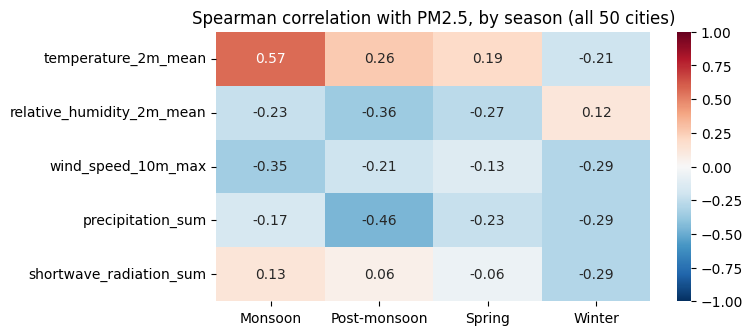

In [15]:
plt.figure(figsize=(7, 3.5))
sns.heatmap(by_season, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation with PM2.5, by season (all 50 cities)")
plt.show()

In [17]:
d = m[(m["city"] == "Delhi") & (m["season"] == "Winter")]
print(len(d))
print(d[cols].corr(method="spearman").loc[weather_cols, "pm2_5_mean"].sort_values().round(2))

481
wind_speed_10m_max          -0.58
shortwave_radiation_sum     -0.44
temperature_2m_mean         -0.20
precipitation_sum            0.03
relative_humidity_2m_mean    0.49
Name: pm2_5_mean, dtype: float64


In [18]:
an = m.copy()
for c in weather_cols + ["pm2_5_mean"]:
    an[c + "_anom"] = an[c] - an.groupby(["city", "month"])[c].transform("mean")

acols = [c + "_anom" for c in weather_cols]
print(an[acols + ["pm2_5_mean_anom"]].corr(method="spearman")
        .loc[acols, "pm2_5_mean_anom"].round(2))

temperature_2m_mean_anom          0.06
relative_humidity_2m_mean_anom   -0.05
wind_speed_10m_max_anom          -0.23
precipitation_sum_anom           -0.15
shortwave_radiation_sum_anom      0.10
Name: pm2_5_mean_anom, dtype: float64


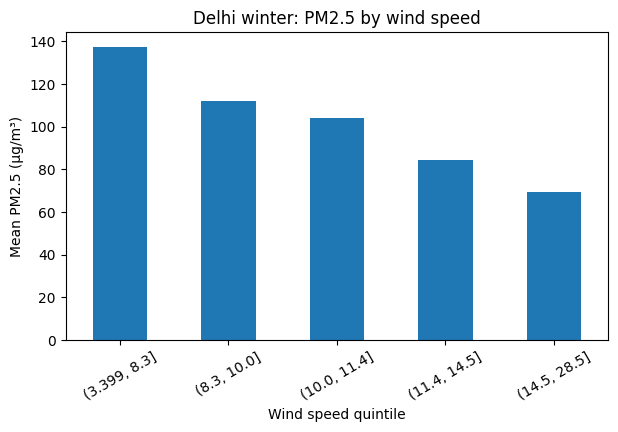

In [19]:
d = d.copy()
d["wind_bin"] = pd.qcut(d[wind_col], 5)
d.groupby("wind_bin", observed=True)["pm2_5_mean"].mean().plot(kind="bar", figsize=(7, 4))
plt.ylabel("Mean PM2.5 (µg/m³)"); plt.xlabel("Wind speed quintile")
plt.title("Delhi winter: PM2.5 by wind speed"); plt.xticks(rotation=30); plt.show()

In [20]:
nm = m[m["season"] != "Monsoon"].copy()
nm["rain"] = np.where(nm[rain_col] > 1, "Rain day (>1 mm)", "Dry day")
print(nm.groupby("rain")["pm2_5_mean"].agg(["count", "mean", "median"]).round(1))
print(nm[nm["city"] == "Delhi"].groupby("rain")["pm2_5_mean"].agg(["count", "mean"]).round(1))

                  count  mean  median
rain                                 
Dry day           43210  45.1    36.9
Rain day (>1 mm)  12940  26.4    21.8
                  count  mean
rain                         
Dry day             981  84.4
Rain day (>1 mm)    142  71.1


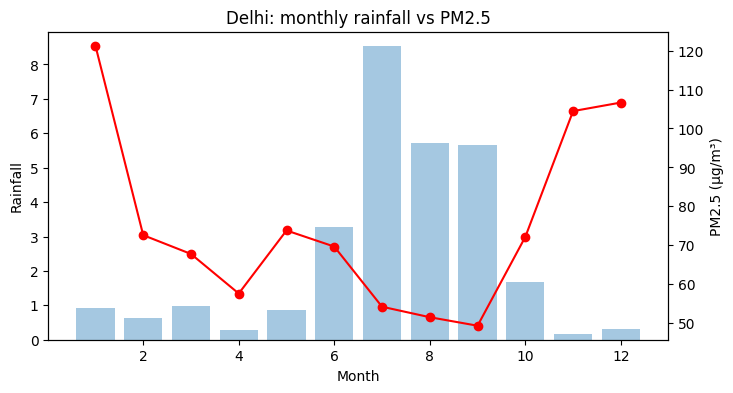

In [21]:
x = m[m["city"] == "Delhi"].groupby("month")[[rain_col, "pm2_5_mean"]].mean()
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(x.index, x[rain_col], alpha=0.4); ax1.set_ylabel("Rainfall")
ax2 = ax1.twinx(); ax2.plot(x.index, x["pm2_5_mean"], color="red", marker="o")
ax2.set_ylabel("PM2.5 (µg/m³)"); ax1.set_xlabel("Month")
plt.title("Delhi: monthly rainfall vs PM2.5"); plt.show()

In [24]:
mon = m[m["season"] == "Monsoon"]
print(mon[["temperature_2m_mean", "precipitation_sum", "pm2_5_mean"]].corr(method="spearman").round(2))

                     temperature_2m_mean  precipitation_sum  pm2_5_mean
temperature_2m_mean                 1.00              -0.24        0.57
precipitation_sum                  -0.24               1.00       -0.17
pm2_5_mean                          0.57              -0.17        1.00


In [25]:
mon = m[m["season"] == "Monsoon"]

# 1. Correlation inside each city, then summarise
per_city = (mon.groupby("city")
              .apply(lambda g: g["temperature_2m_mean"].corr(g["pm2_5_mean"], method="spearman")))
print(per_city.describe().round(2))
print(per_city.sort_values().head(5).round(2))
print(per_city.sort_values().tail(5).round(2))

# 2. Remove each city's own monsoon average, then correlate
mon = mon.copy()
for c in ["temperature_2m_mean", "pm2_5_mean"]:
    mon[c + "_dev"] = mon[c] - mon.groupby("city")[c].transform("mean")
print(mon[["temperature_2m_mean_dev", "pm2_5_mean_dev"]].corr(method="spearman").round(2))

count    50.00
mean      0.27
std       0.16
min      -0.17
25%       0.17
50%       0.31
75%       0.39
max       0.55
dtype: float64
city
Madurai      -0.17
Puducherry   -0.06
Mangaluru    -0.06
Mumbai       -0.02
Chennai       0.00
dtype: float64
city
Mysuru        0.44
Port Blair    0.45
Amritsar      0.49
Ludhiana      0.51
Coimbatore    0.55
dtype: float64
                         temperature_2m_mean_dev  pm2_5_mean_dev
temperature_2m_mean_dev                     1.00            0.26
pm2_5_mean_dev                              0.26            1.00


/tmp/ipykernel_50/3062253805.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g["temperature_2m_mean"].corr(g["pm2_5_mean"], method="spearman")))


In [28]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/air_quality_daily.csv", parse_dates=["date"])

print("duplicate city-date rows:", df.duplicated(["city", "date"]).sum())
print("negative values:", (df.select_dtypes("number") < 0).sum().sum())

duplicate city-date rows: 0
negative values: 0


In [23]:
by_season.to_csv("/kaggle/working/corr_by_season.csv")
corr_all.to_csv("/kaggle/working/corr_overall.csv")